# Assessing the Relationship Between Diet and Mental Health in High Schoolers

**Team members:** Nathan Park, Amelia Chen, Lawson Pham, Amran Belete

**Repository:** (https://github.com/lawsonpham/project_template)

## Setup

Use relative paths and keep the notebook runnable from beginning to end.

In [2]:
from pathlib import Path

DATA_DIR = Path("data")
assert DATA_DIR.is_dir(), "The data directory is missing."

import pandas as pd
import numpy as np

## Load data

In [3]:
# Source: https://ccani007.github.io/dissertationData/

df2015 = pd.read_csv(DATA_DIR/"raw2015.csv")
df2017 = pd.read_csv(DATA_DIR/"raw2017.csv")
df2019 = pd.read_csv(DATA_DIR/"raw2019.csv")

## Prepare data

##### Step 1

- 2015: https://www.cdc.gov/yrbs/files/2015/pdf/2015_yrbs-data-users_guide_smy_combined.pdf
- 2017: https://www.cdc.gov/yrbs/files/2017/pdf/2017_YRBS_Data_Users_Guide.pdf
- 2019: https://www.cdc.gov/yrbs/files/2019/pdf/2019_National_YRBS_Data_Users_Guide.pdf

Identify questions relevant for baseline, mental health, diet, sleep, and screen time analysis. Create a short and standardized label for each question. For each dataset (2015/2017/2019), note the question number.


| Label                   | 2015 | 2017 | 2019 |
| ----------------------- | ---- | ---- | ---- |
| Age                     | 1    | -    | -    |
| Sex                     | 2    | -    | -    |
| Grade                   | 3    | -    | -    |
| Hopelessness            | 26   | 25   | -    |
| SuicidalIdeation        | 27   | 26   | -    |
| SuicidePlan             | 28   | 27   | -    |
| SuicideAttempts         | 29   | 28   | -    |
| SuicideAttemptTreatment | 30   | 29   | -    |
| WeightDescription       | 69   | 68   | 67   |
| WeightGoals             | 70   | 69   | 68   |
| FruitJuiceConsumption   | 71   | 70   | 69   |
| FruitConsumption        | 72   | 71   | 70   |
| SaladConsumption        | 73   | 72   | 71   |
| PotatoConsumption       | 74   | 73   | 72   |
| CarrotConsumption       | 75   | 74   | 73   |
| VeggieConsumption       | 76   | 75   | 74   |
| SodaConsumption         | 77   | 76   | 75   |
| MilkConsumption         | 78   | 77   | 76   |
| BreakfastConsumption    | 79   | 78   | 77   |
| TVHours                 | 81   | 80   | 79   |
| ScreenTimeHours         | 82   | 81   | 80   |
| SleepHours              | 88   | -    | -    |
| SportsDrinkConsumption  | 92   | -    | -    |
| WaterConsumption        | 93   | -    | -    |

(Note: "-" represents carrying over the question number from the column to the left)


In [ ]:
# Clean data and create features.

# Sources: 
# https://stackoverflow.com/questions/34682828/extracting-specific-selected-columns-to-new-dataframe-as-a-copy
# https://www.statology.org/pandas-rename-columns-with-dictionary/
# https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf

'''
initial approach to all 3 datasets:
    1. extract the relevant columns to a new dataframe
    2. create a dictionary associating questions and labels
    3. rename the columns in the new dataframe using the dictionary
'''

df2015_clean = df2015[['Q1', 'Q2', 'Q3', 'Q26', 'Q27', 'Q28', 'Q29', 'Q30', 
                       'Q69', 'Q70', 'Q71', 'Q72', 'Q73', 'Q74', 'Q75', 'Q76', 
                       'Q77', 'Q78', 'Q79', 'Q81', 'Q82', 'Q88', 'Q92', 'Q93',]].copy()

labels2015 = { 'Q1' : 'Age',
               'Q2' : 'Sex',
               'Q3' : 'Grade',
               'Q26' : 'Hopelessness',
               'Q27' : 'SuicidalIdeation',
               'Q28' : 'SuicidePlan',
               'Q29' : 'SuicideAttempts',
               'Q30' : 'SuicideAttemptTreatment',
               'Q69' : 'WeightDescription',
               'Q70' : 'WeightGoals',
               'Q71' : 'FruitJuiceConsumption',
               'Q72' : 'FruitConsumption',
               'Q73' : 'SaladConsumption',
               'Q74' : 'PotatoConsumption',
               'Q75' : 'CarrotConsumption',
               'Q76' : 'VeggieConsumption',
               'Q77' : 'SodaConsumption',
               'Q78' : 'MilkConsumption',
               'Q79' : 'BreakfastConsumption',
               'Q81' : 'TVHours',
               'Q82' : 'ScreenTimeHours',
               'Q88' : 'SleepHours',
               'Q92' : 'SportsDrinkConsumption',
               'Q93' : 'WaterConsumption'}

df2015_clean = df2015_clean.rename(columns = labels2015)


df2017_clean = df2017[['Q1', 'Q2', 'Q3', 'Q25', 'Q26', 'Q27', 'Q28', 'Q29', 
                       'Q68', 'Q69', 'Q70', 'Q71', 'Q72', 'Q73', 'Q74', 'Q75', 
                       'Q76', 'Q77', 'Q78', 'Q80', 'Q81', 'Q88', 'Q92', 'Q93',]].copy()

labels2017 = { 'Q1' : 'Age',
               'Q2' : 'Sex',
               'Q3' : 'Grade',
               'Q25' : 'Hopelessness',
               'Q26' : 'SuicidalIdeation',
               'Q27' : 'SuicidePlan',
               'Q28' : 'SuicideAttempts',
               'Q29' : 'SuicideAttemptTreatment',
               'Q68' : 'WeightDescription',
               'Q69' : 'WeightGoals',
               'Q70' : 'FruitJuiceConsumption',
               'Q71' : 'FruitConsumption',
               'Q72' : 'SaladConsumption',
               'Q73' : 'PotatoConsumption',
               'Q74' : 'CarrotConsumption',
               'Q75' : 'VeggieConsumption',
               'Q76' : 'SodaConsumption',
               'Q77' : 'MilkConsumption',
               'Q78' : 'BreakfastConsumption',
               'Q80' : 'TVHours',
               'Q81' : 'ScreenTimeHours',
               'Q88' : 'SleepHours',
               'Q92' : 'SportsDrinkConsumption',
               'Q93' : 'WaterConsumption'}

df2017_clean = df2017_clean.rename(columns = labels2017)


df2019_clean = df2019[['Q1', 'Q2', 'Q3', 'Q25', 'Q26', 'Q27', 'Q28', 'Q29', 
                       'Q67', 'Q68', 'Q69', 'Q70', 'Q71', 'Q72', 'Q73', 'Q74', 
                       'Q75', 'Q76', 'Q77', 'Q79', 'Q80', 'Q88', 'Q92', 'Q93',]].copy()

labels2019 = { 'Q1' : 'Age',
               'Q2' : 'Sex',
               'Q3' : 'Grade',
               'Q25' : 'Hopelessness',
               'Q26' : 'SuicidalIdeation',
               'Q27' : 'SuicidePlan',
               'Q28' : 'SuicideAttempts',
               'Q29' : 'SuicideAttemptTreatment',
               'Q67' : 'WeightDescription',
               'Q68' : 'WeightGoals',
               'Q69' : 'FruitJuiceConsumption',
               'Q70' : 'FruitConsumption',
               'Q71' : 'SaladConsumption',
               'Q72' : 'PotatoConsumption',
               'Q73' : 'CarrotConsumption',
               'Q74' : 'VeggieConsumption',
               'Q75' : 'SodaConsumption',
               'Q76' : 'MilkConsumption',
               'Q77' : 'BreakfastConsumption',
               'Q79' : 'TVHours',
               'Q80' : 'ScreenTimeHours',
               'Q88' : 'SleepHours',
               'Q92' : 'SportsDrinkConsumption',
               'Q93' : 'WaterConsumption'}

df2019_clean = df2019_clean.rename(columns = labels2019)


combined_yrbs = pd.concat([df2015_clean, df2017_clean, df2019_clean])

'''
# check: 15624+14765+13677=44066
print("df2015 dimensions: ", df2015_clean.shape)
print("df2017 dimensions: ", df2017_clean.shape)
print("df2019 dimensions: ", df2019_clean.shape)
print()
print("combined dimensions: ", combined_yrbs.shape)
'''

combined_yrbs = combined_yrbs.astype('category')

age = { 1 : '12 or younger',
        2 : '13',
        3 : '14',
        4 : '15',
        5 : '16',
        6 : '17',
        7 : '18 or older'}

combined_yrbs['Age'] = combined_yrbs['Age'].cat.rename_categories(age)

sex = { 1 : 'Female',
        2 : 'Male'}

combined_yrbs['Sex'] = combined_yrbs['Sex'].cat.rename_categories(sex)

grade = { 1 : '9',
          2 : '10',
          3 : '11',
          4 : '12',
          5 : 'other/ungraded'}

combined_yrbs['Grade'] = combined_yrbs['Grade'].cat.rename_categories(grade)

# use for Hopelessness, SuicidalIdeation, SuicidePlan
yes_no = { 1 : 'yes',
           2 : 'no'}

combined_yrbs['Hopelessness'] = combined_yrbs['Hopelessness'].cat.rename_categories(yes_no)
combined_yrbs['SuicidalIdeation'] = combined_yrbs['SuicidalIdeation'].cat.rename_categories(yes_no)
combined_yrbs['SuicidePlan'] = combined_yrbs['SuicidePlan'].cat.rename_categories(yes_no)

suicide_attempts = { 1 : '0',
                    2 : '1',
                    3 : '2-3',
                    4 : '4-5',
                    5 : '6+'}

combined_yrbs['SuicideAttempts'] = combined_yrbs['SuicideAttempts'].cat.rename_categories(suicide_attempts)

suicide_attempt_treatment = { 1 : 'no attempt',
                              2 : 'yes',
                              3 : 'no'}

combined_yrbs['SuicideAttemptTreatment'] = combined_yrbs['SuicideAttemptTreatment'].cat.rename_categories(suicide_attempt_treatment)

weight = { 1 : 'very underweight',
           2 : 'slightly underweight',
           3 : 'right weight',
           4 : 'slightly overweight',
           5 : 'very overweight'}

combined_yrbs['WeightDescription'] = combined_yrbs['WeightDescription'].cat.rename_categories(weight)

weight_goals = { 1 : 'lose weight',
                 2 : 'gain weight',
                 3 : 'maintain weight',
                 4 : 'none'}

combined_yrbs['WeightGoals'] = combined_yrbs['WeightGoals'].cat.rename_categories(weight_goals)

# use for all consumption questions except breakfast
consumption_rates = { 1 : 'none',
                      2 : '1-3',
                      3 : '4-6',
                      4 : '1 per day',
                      5 : '2 per day',
                      6 : '3 per day',
                      7 : '4+ per day'}

consumption_categories = ['FruitJuiceConsumption', 'FruitConsumption', 'SaladConsumption', 
                          'PotatoConsumption', 'CarrotConsumption', 'VeggieConsumption', 
                          'SodaConsumption', 'MilkConsumption', 'SportsDrinkConsumption','WaterConsumption']

for i in range(10):
    combined_yrbs[consumption_categories[i]] = combined_yrbs[consumption_categories[i]].cat.rename_categories(consumption_rates)

breakfast = { 1 : '0',
              2 : '1',
              3 : '2',
              4 : '3',
              5 : '4',
              6 : '5',
              7 : '6',
              8 : '7'}

combined_yrbs['BreakfastConsumption'] = combined_yrbs['BreakfastConsumption'].cat.rename_categories(breakfast)

tv_screen_time = { 1 : 'none',
                   2 : 'less than 1',
                   3 : '1',
                   4 : '2',
                   5 : '3',
                   6 : '4',
                   7 : '5+'}

combined_yrbs['TVHours'] = combined_yrbs['TVHours'].cat.rename_categories(tv_screen_time)
combined_yrbs['ScreenTimeHours'] = combined_yrbs['ScreenTimeHours'].cat.rename_categories(tv_screen_time)

sleep = { 1 : '4 or less',
          2 : '5',
          3 : '6',
          4 : '7',
          5 : '8',
          6 : '9',
          7 : '10 or more'}

combined_yrbs['SleepHours'] = combined_yrbs['SleepHours'].cat.rename_categories(sleep)

combined_yrbs.to_csv('data/combined_yrbs_clean.csv', index=False)


## Explore data

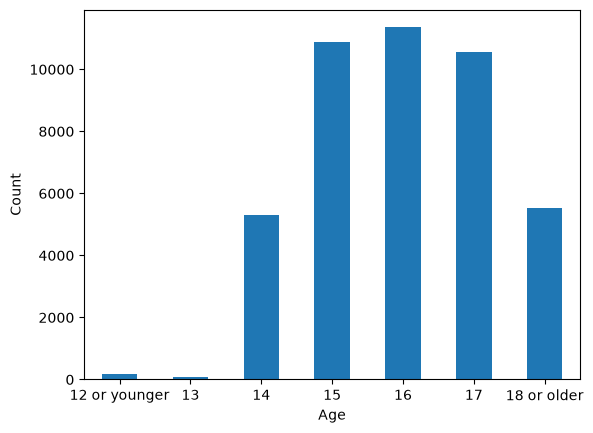

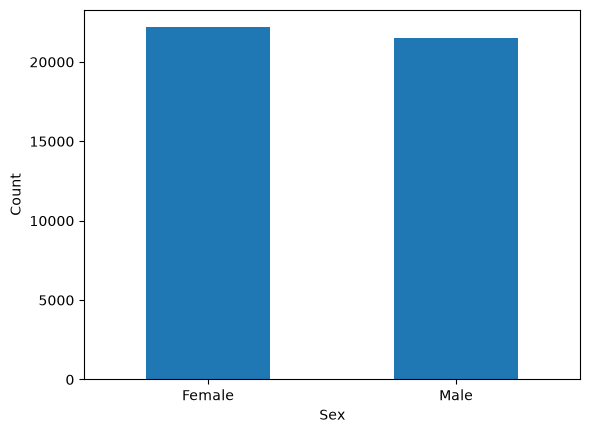

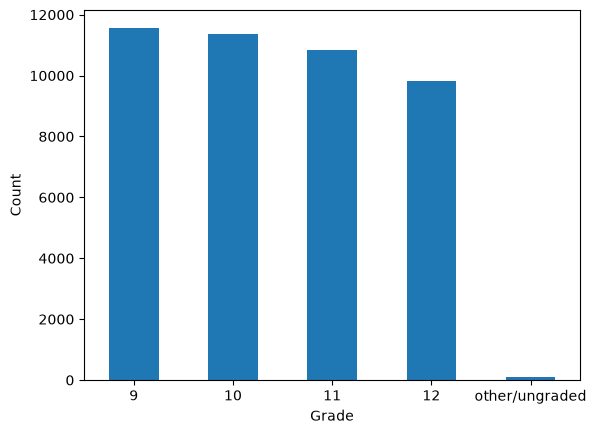

In [ ]:
# Summarize and visualize the prepared data.


## Build models

In [ ]:
# Train baseline and candidate models.

## Evaluate models

In [ ]:
# Compare models using the chosen evaluation measures.

# 3 models

## Final results

In [ ]:
# Generate the final tables and figures.

# discrete scale

## AI usage disclosure

- **AI tool/model:** [Name the tool and model, or state that no generative AI was used.]
- **Used for:** [Briefly identify the tasks.]
- **How we verified the work:** [Briefly identify the checks.]
- **Prompt(s) used:** [Paste the prompts used.]